# Declaration of Originality

**School of Informatics & IT**
<br/>**Diploma in Applied Artificial Intelligence**
<br/>**Machine Learning for Developers (CAI2C08)**
<br/>**AY2026/2027 April Semester**
<br/>**Program Codes**

* Student Name: Syed Ghazi Bin Syed Muhammad Shafeeq Alsagoff



**Declaration of Originality**
* I am the originator of this work, and I have appropriately acknowledged all other original sources used as my references for this work.
* I understand that Plagiarism is the act of taking and using the whole or any part of another person’s work, including work generated by AI, and presenting it as my own.
* I understand that Plagiarism is an academic offence and if I am found to have committed or abetted the offence of plagiarism in relation to this submitted work, disciplinary action will be enforced.

# Libraries

In [1]:
## Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, root_mean_squared_error


## Setup (shared settings and evaluation function)

In [2]:
## Shared settings used by every cycle, and a reusable evaluation function
file_path = "Life Expectancy Data.csv"
test_size = 0.3
random_state = 2026
param_dist_rfr = {'n_estimators': [50, 100, 150], 'max_depth': [10, 20, 30], 'min_samples_split': [2, 5, 10]}
results = []

def evaluate(model, name, X_te, y_te):
    y_pred = model.predict(X_te)
    row = {'Model': name,
           'MAE':  round(mean_absolute_error(y_te, y_pred), 3),
           'MSE':  round(mean_squared_error(y_te, y_pred), 3),
           'RMSE': round(root_mean_squared_error(y_te, y_pred), 3)}
    results.append(row)
    print(f"--- {name} ---")
    print(f"MAE : {row['MAE']} | MSE: {row['MSE']} | RMSE: {row['RMSE']}\n")
    return row

# 1. Business Understanding
Goal: Predict a country's life expectency in terms of years based on health, economic, and social indicators. The target is numeric, thus it is a regression problem. When it comes to business, this helps health ministries and NGOs identify which factorss most affect life expectancy and priroitise where to invest.

# 2. Data Understanding

## 2.1 Load dataset

In [3]:
## Read *.csv file into pandas DataFrame
file_path = "Life Expectancy Data.csv"
df = pd.read_csv(file_path)
df.columns = df.columns.str.strip()  # Remove leading/trailing whitespace from column names
df

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2933,Zimbabwe,2004,Developing,44.3,723.0,27,4.36,0.000000,68.0,31,...,67.0,7.13,65.0,33.6,454.366654,12777511.0,9.4,9.4,0.407,9.2
2934,Zimbabwe,2003,Developing,44.5,715.0,26,4.06,0.000000,7.0,998,...,7.0,6.52,68.0,36.7,453.351155,12633897.0,9.8,9.9,0.418,9.5
2935,Zimbabwe,2002,Developing,44.8,73.0,25,4.43,0.000000,73.0,304,...,73.0,6.53,71.0,39.8,57.348340,125525.0,1.2,1.3,0.427,10.0
2936,Zimbabwe,2001,Developing,45.3,686.0,25,1.72,0.000000,76.0,529,...,76.0,6.16,75.0,42.1,548.587312,12366165.0,1.6,1.7,0.427,9.8


## 2.2 Summary Statistics

In [4]:
## Understand the type of variable for each column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   object 
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   object 
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10  BMI                              2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  
 12  Polio               

In [5]:

## Check for missing data
df.isna().sum()

Country                              0
Year                                 0
Status                               0
Life expectancy                     10
Adult Mortality                     10
infant deaths                        0
Alcohol                            194
percentage expenditure               0
Hepatitis B                        553
Measles                              0
BMI                                 34
under-five deaths                    0
Polio                               19
Total expenditure                  226
Diphtheria                          19
HIV/AIDS                             0
GDP                                448
Population                         652
thinness  1-19 years                34
thinness 5-9 years                  34
Income composition of resources    167
Schooling                          163
dtype: int64

In [6]:
## Describe data distribution
df.describe(include='all')

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
count,2938,2938.000000,2938,2928.000000,2928.000000,2938.000000,2744.000000,2938.000000,2385.000000,2938.000000,...,2919.000000,2712.00000,2919.000000,2938.000000,2490.000000,2.286000e+03,2904.000000,2904.000000,2771.000000,2775.000000
unique,193,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,Afghanistan,NaN,Developing,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,16,NaN,2426,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,2007.518720,NaN,69.224932,164.796448,30.303948,4.602861,738.251295,80.940461,2419.592240,...,82.550188,5.93819,82.324084,1.742103,7483.158469,1.275338e+07,4.839704,4.870317,0.627551,11.992793
std,NaN,4.613841,NaN,9.523867,124.292079,117.926501,4.052413,1987.914858,25.070016,11467.272489,...,23.428046,2.49832,23.716912,5.077785,14270.169342,6.101210e+07,4.420195,4.508882,0.210904,3.358920
min,NaN,2000.000000,NaN,36.300000,1.000000,0.000000,0.010000,0.000000,1.000000,0.000000,...,3.000000,0.37000,2.000000,0.100000,1.681350,3.400000e+01,0.100000,0.100000,0.000000,0.000000
25%,NaN,2004.000000,NaN,63.100000,74.000000,0.000000,0.877500,4.685343,77.000000,0.000000,...,78.000000,4.26000,78.000000,0.100000,463.935626,1.957932e+05,1.600000,1.500000,0.493000,10.100000
50%,NaN,2008.000000,NaN,72.100000,144.000000,3.000000,3.755000,64.912906,92.000000,17.000000,...,93.000000,5.75500,93.000000,0.100000,1766.947595,1.386542e+06,3.300000,3.300000,0.677000,12.300000
75%,NaN,2012.000000,NaN,75.700000,228.000000,22.000000,7.702500,441.534144,97.000000,360.250000,...,97.000000,7.49250,97.000000,0.800000,5910.806335,7.420359e+06,7.200000,7.200000,0.779000,14.300000


## 2.3 Data Visualization

### 2.3.1 Understanding distribution of data

### 2.3.1.1 Understanding distribution of target

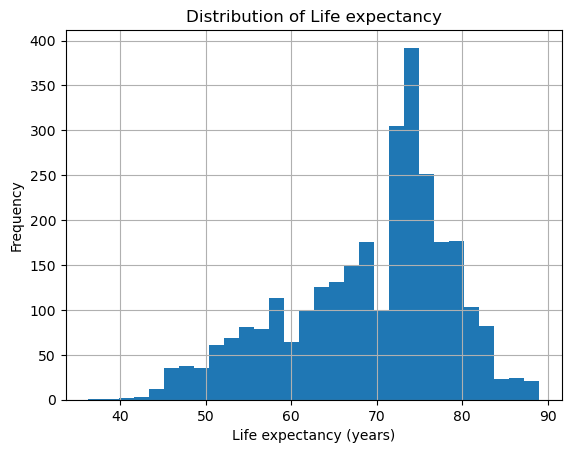

In [7]:
## Understanding distribution of target
col_y = 'Life expectancy'
# Plotting histogram for the target variable
df[col_y].hist(bins=30)
plt.title('Distribution of Life expectancy')
plt.xlabel('Life expectancy (years)')
plt.ylabel('Frequency')
plt.show()

### 2.3.1.2 Understanding distribution of features

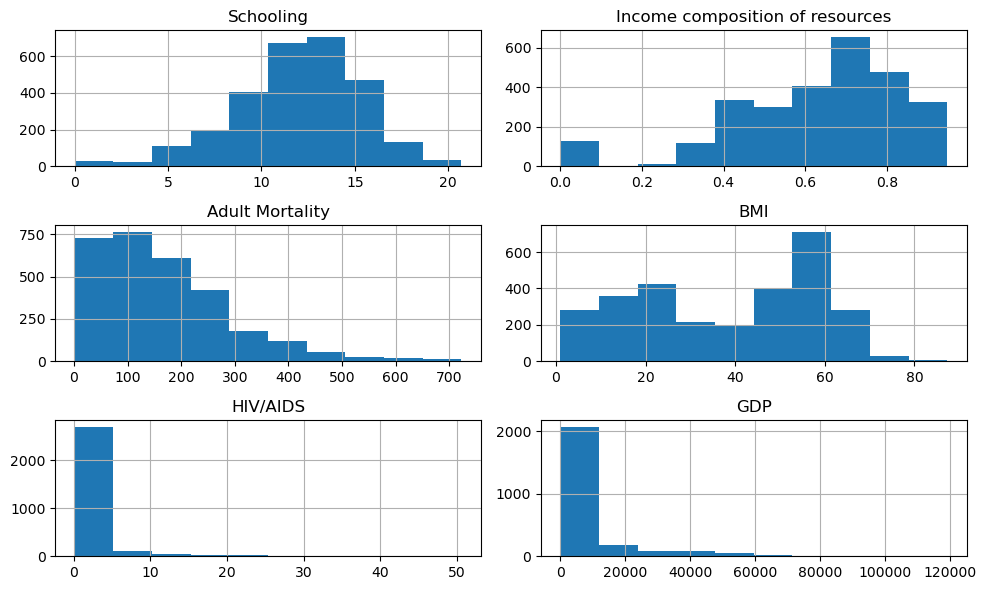

In [8]:
## Understanding distribution of features
col_features = ['Schooling', 'Income composition of resources',
                'Adult Mortality', 'BMI', 'HIV/AIDS', 'GDP']
df[col_features].hist(figsize=(10, 6)) # Plotting histograms for each feature
plt.tight_layout()
plt.show()

### 2.3.2 Understanding relationship between variables

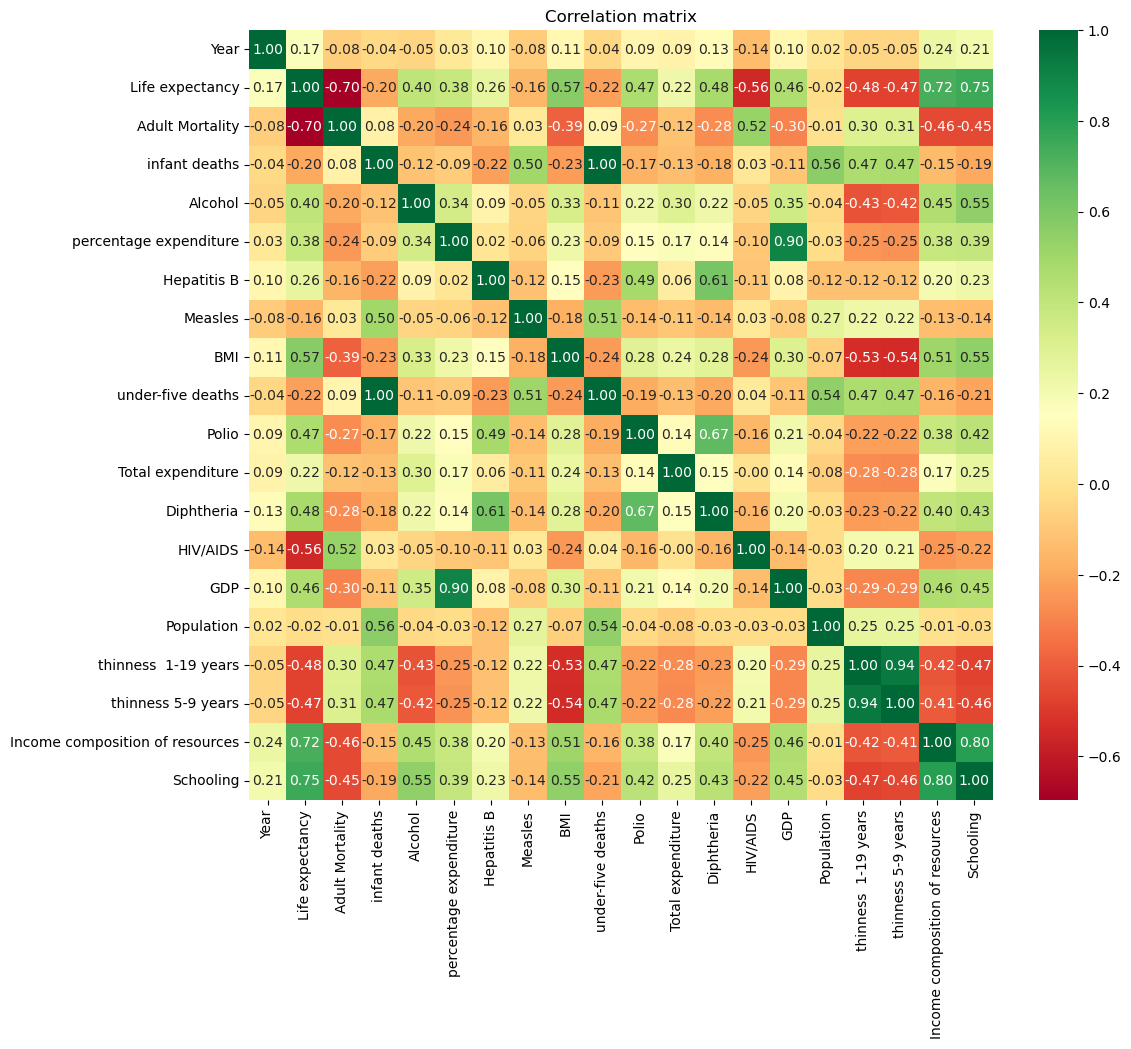

In [9]:
## Understanding relationship between variables
col_numeric = df.select_dtypes(include=['float', 'int']).columns
df_corr = df[col_numeric].corr()
# Plotting the correlation matrix
plt.figure(figsize=(12, 10))
sns.heatmap(df_corr, cmap='RdYlGn', annot=True, fmt='.2f')
plt.title('Correlation matrix')
plt.show()

# 3. Data Preparation

## 3.1 Data Cleaning

Baseline strategy: drop the Country column, then drop any rows that contain missing
values (dropna). A later iteration will replace this with imputation.

In [10]:
## Baseline cleaning: drop Country, then drop rows with any missing value
df = pd.read_csv(file_path)
df.columns = df.columns.str.strip()
df = df.drop('Country', axis=1)     # 193 categories -> too many for one-hot
df = df.dropna()                    # baseline: drop rows with any missing value

y = df['Life expectancy']
X = pd.get_dummies(df.drop('Life expectancy', axis=1), drop_first=True)
print('Baseline rows:', len(X))

Baseline rows: 1649


## Feature Dictionary

**Target:** `Life Expectancy` (years) - numeric, so this is a regression problem.

**Features used in the model (14):**

| Feature | What it is | Corr. with target | Why kept |

| Schooling | Avg years of education | +0.75 | Strongest single predictor; proxy for development |

| Income composition of resources | HDI-style index (0-1) | +0.73 | Top Features by Random Forest importance |

| Adult Mortality | Deaths 15-60 per 1000 | -0.70 | Direct Mortality signal |

| BMI | Average body mass index| +0.57 | Reflects national nutrition/wealth |

| HIV/Aids | Deaths per 1000 | -0.56 | 2nd by importance; major driver in high-prevalence countries |

| Immunization avg | Mean of Polio and Diphtheria (%) | +-0.47 | Engineered feature combining two vaccines columns |

| GDP | GDP per capita (USD) | +0.46 | Economic capacity for healthcare | 

| Thinness  1-19 years | Malnutrition in youth (%) | -0.48 | Nutrition signal (Opposite of BMI) |

| Alcohol | Litres per capita | +0.40 | Co-moves with national wealth |

| percentage expenditure | Health spend as % of GDP p.c. | +0.38 | Health investment level |

| under-five deaths | Child mortality per 1000 | -0.22 | Child-health signal | 

| Total expenditure | Govt health spend (%) | +0.22 | Health Investment level |

| Measels | Reported cases | -0.16 | Disease-burden signal |

| Status_Developing | Developed/Developing flag (one-hot) | n/a | Development context |

**Features dropped, and why:**

- `Country` - 193 unique values; too high cardinality for one-hot encoding.
- `Year` - a time index, not a health indicator.
- `Population` - most missing values (652) **and** near-zero correlation (-0.02).
- `Hepatits B` - heavy missingness (533) and redundant with other immunisation features.
- `Polio`, `Diphtheria` - merged into the engineered `Immunization avg`.
- `infant deaths` - near-duplicate of `under-five deaths`.
- `thinness 5-9 years` - near-duplicate of `thinness 1-19 years`.

**Notes:**
- **Correlation is not the same as importance.** Schooling has the highest correlation, but the Random Forest ranks Income composition and HIV/Aids as most important, because Schooling and Income composition are hgihly correlated (multicollinearity) , so the tree only needs one of them.

- **No scaling needed** - Random Forest splits on the thresholds, so it is unaffected by the different feature scales.

- Some positive signs (Alcohol, BMI) are correlation at the country level, not causation - they co-move with national wealth.

## 3.2 Train-Test Split

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=random_state)

# 4. Modelling

I develop the model in cycles. Each cycle reloads the raw data and redoes the
preparation from scratch, so every cycle is self-contained and reproducible.
- Cycle 1 (baseline): train four models on basic features, then tune the best.
- Iteration 1: add feature engineering, retrain and re-tune.
- Iteration 2: use feature importance to select features, retrain and re-tune.

## 4.1 Train Model

In [12]:
## Train the four models on the basic features
linr = LinearRegression().fit(X_train, y_train)
dtr  = DecisionTreeRegressor(random_state=random_state).fit(X_train, y_train)
rfr  = RandomForestRegressor(n_estimators=100, random_state=random_state, n_jobs=-1).fit(X_train, y_train)
gbr  = GradientBoostingRegressor(random_state=random_state).fit(X_train, y_train)

evaluate(linr, 'Baseline - Linear Regression', X_test, y_test)
evaluate(dtr,  'Baseline - Decision Tree',     X_test, y_test)
evaluate(rfr,  'Baseline - Random Forest',     X_test, y_test)
evaluate(gbr,  'Baseline - Gradient Boosting', X_test, y_test)

--- Baseline - Linear Regression ---
MAE : 2.812 | MSE: 13.368 | RMSE: 3.656

--- Baseline - Decision Tree ---
MAE : 1.523 | MSE: 6.376 | RMSE: 2.525

--- Baseline - Random Forest ---
MAE : 1.128 | MSE: 3.417 | RMSE: 1.848

--- Baseline - Gradient Boosting ---
MAE : 1.503 | MSE: 4.644 | RMSE: 2.155



{'Model': 'Baseline - Gradient Boosting',
 'MAE': 1.503,
 'MSE': 4.644,
 'RMSE': 2.155}

## 4.2 Hyperparameter Tuning

Random Forest is the best baseline model, so it is tuned here with RandomizedSearchCV
(max 3 values per hyperparameter). Tuning the baseline keeps the comparison with later
iterations fair.

In [13]:
rs_base = RandomizedSearchCV(RandomForestRegressor(random_state=random_state, n_jobs=-1),
                             param_dist_rfr, n_iter=6, cv=3,
                             scoring='neg_mean_absolute_error', random_state=random_state, n_jobs=-1)
rs_base.fit(X_train, y_train)
print('Baseline best parameters:', rs_base.best_params_)
rf_base = rs_base.best_estimator_
evaluate(rf_base, 'Baseline - Random Forest (tuned)', X_test, y_test)

Baseline best parameters: {'n_estimators': 100, 'min_samples_split': 2, 'max_depth': 20}
--- Baseline - Random Forest (tuned) ---
MAE : 1.126 | MSE: 3.422 | RMSE: 1.85



{'Model': 'Baseline - Random Forest (tuned)',
 'MAE': 1.126,
 'MSE': 3.422,
 'RMSE': 1.85}

# 5. Model Evaluation

## Choice of evaluation metrics

This is a regression problem, so I evaluate with error-based metrics that are in the same
unit as the target (years):

- **MAE (Mean Absolute Error)** is my main metric - the average error in years, easy to
  explain: "on average the prediction is off by about X years."
- **RMSE (Root Mean Squared Error)** is my supporting metric - it squares errors before
  averaging, so it punishes large mistakes more than MAE.
- **MSE** is reported for completeness (RMSE is its square root).

I deliberately avoid R2: it is a relative score, not an error in the target's unit; it can
be inflated just by adding features; and a high R2 can hide large individual errors. MAE
and RMSE show more honestly how many years off the model is.

**Observation - baseline models.** The four models rank clearly on the basic features.
Linear Regression is weakest (MAE 2.81, RMSE 3.66) because life expectancy does not vary
linearly with skewed features like GDP and HIV/AIDS. The single Decision Tree is better
(MAE 1.52) but overfits the training data. The two ensembles win: Random Forest (MAE
1.13, RMSE 1.85) edges out Gradient Boosting (MAE 1.50, RMSE 2.16). Tuning the Random
Forest barely changes it (MAE 1.13 -> 1.13), which tells me the model is already near its
ceiling for this feature set - so the biggest gains must come from the DATA, not the
hyperparameters. Random Forest is carried forward as the model to improve.

In [14]:
new_data = X_test.iloc[[0]]
print('Predicted life expectancy (years):', rf_base.predict(new_data))
print('Actual life expectancy (years):', y_test.iloc[0])

Predicted life expectancy (years): [81.87828571]
Actual life expectancy (years): 81.9


# Iterative model development

## Iteration 1 - Imputation, Feature Engineering and Tuning

This iteration reloads the raw data and redoes the cleaning. Instead of DROPPING rows
with missing values, it IMPUTES them with the column median, which keeps far more data
(2,928 rows vs 1,649). It also engineers 'Immunization avg' and drops redundant columns.

In [15]:
## Iteration 1: reload and redo cleaning, this time IMPUTING instead of dropping rows
df = pd.read_csv(file_path)
df.columns = df.columns.str.strip()
df = df.drop(['Country', 'Population', 'Hepatitis B', 'Year'], axis=1)   # drop low-value / high-missing columns
df = df.dropna(subset=['Life expectancy'])                              # only drop rows missing the TARGET (never impute the target)

## Impute remaining missing feature values with the column median
feature_cols = df.drop('Life expectancy', axis=1).select_dtypes(include=['float', 'int']).columns
df[feature_cols] = df[feature_cols].fillna(df[feature_cols].median())

## Feature engineering
df['Immunization avg'] = (df['Polio'] + df['Diphtheria']) / 2
df = df.drop(['Polio', 'Diphtheria', 'infant deaths', 'thinness 5-9 years'], axis=1)

y2 = df['Life expectancy']
X2 = pd.get_dummies(df.drop('Life expectancy', axis=1), drop_first=True)
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=test_size, random_state=random_state)
print('Iteration 1 rows:', len(X2))

Iteration 1 rows: 2928


In [16]:
## Iteration 1: retrain and tune Random Forest on the imputed, engineered data
rfr_i1 = RandomForestRegressor(n_estimators=100, random_state=random_state, n_jobs=-1).fit(X2_train, y2_train)
evaluate(rfr_i1, 'Iteration 1 - Random Forest', X2_test, y2_test)

rs_i1 = RandomizedSearchCV(RandomForestRegressor(random_state=random_state, n_jobs=-1),
                           param_dist_rfr, n_iter=6, cv=3,
                           scoring='neg_mean_absolute_error', random_state=random_state, n_jobs=-1)
rs_i1.fit(X2_train, y2_train)
print('Iteration 1 best parameters:', rs_i1.best_params_)
rf_iter1 = rs_i1.best_estimator_
evaluate(rf_iter1, 'Iteration 1 - Random Forest (tuned)', X2_test, y2_test)

--- Iteration 1 - Random Forest ---
MAE : 1.159 | MSE: 3.283 | RMSE: 1.812

Iteration 1 best parameters: {'n_estimators': 100, 'min_samples_split': 2, 'max_depth': 20}
--- Iteration 1 - Random Forest (tuned) ---
MAE : 1.16 | MSE: 3.278 | RMSE: 1.811



{'Model': 'Iteration 1 - Random Forest (tuned)',
 'MAE': 1.16,
 'MSE': 3.278,
 'RMSE': 1.811}

**Observation - Iteration 1.** Instead of throwing away the 1,289 rows that contain any
missing value, I impute them with the column median. This nearly doubles the usable data
(1,649 -> 2,928 rows). Even though the test set is now larger and includes harder-to-
predict countries, RMSE actually falls slightly (1.85 -> 1.81) while MAE stays around
1.16. The real win is that the model now learns from far more of the world's countries,
which makes it more robust and representative. Note: because imputation changes the row
count, the baseline and Iteration 1 are tested on different rows, so I treat this as a
data-quality improvement rather than a strict metric-to-metric comparison.

## Iteration 2 - Feature Selection and Tuning

In [17]:
## Iteration 2: keep the smallest set of features that reach 90% of total importance
imp_sorted = pd.Series(rf_iter1.feature_importances_, index=X2.columns).sort_values(ascending=False)
cumulative = imp_sorted.cumsum()
n_keep = int((cumulative < 0.90).sum()) + 1
selected_features = imp_sorted.index[:n_keep].tolist()
print(f'Selected {len(selected_features)} of {len(imp_sorted)} features:', selected_features)

X3_train, X3_test = X2_train[selected_features], X2_test[selected_features]

rs_i2 = RandomizedSearchCV(RandomForestRegressor(random_state=random_state, n_jobs=-1),
                           param_dist_rfr, n_iter=6, cv=3,
                           scoring='neg_mean_absolute_error', random_state=random_state, n_jobs=-1)
rs_i2.fit(X3_train, y2_train)
print('Iteration 2 best parameters:', rs_i2.best_params_)
rf_iter2 = rs_i2.best_estimator_
evaluate(rf_iter2, 'Iteration 2 - Random Forest (selected, tuned)', X3_test, y2_test)

Selected 4 of 14 features: ['HIV/AIDS', 'Adult Mortality', 'Income composition of resources', 'under-five deaths']
Iteration 2 best parameters: {'n_estimators': 100, 'min_samples_split': 2, 'max_depth': 20}
--- Iteration 2 - Random Forest (selected, tuned) ---
MAE : 1.281 | MSE: 3.741 | RMSE: 1.934



{'Model': 'Iteration 2 - Random Forest (selected, tuned)',
 'MAE': 1.281,
 'MSE': 3.741,
 'RMSE': 1.934}

**Observation - Iteration 2.** Feature importance shows the prediction is dominated by
just four features (HIV/AIDS, Adult Mortality, Income composition and under-five deaths),
which alone make up 90% of the total importance. I build a model on only those four -
and because it is tested on the SAME rows as Iteration 1, this is a fair, direct
comparison. It scores MAE 1.28 and RMSE 1.93, clearly worse than Iteration 1's full model
(MAE 1.16, RMSE 1.81). So the smaller features still add value and should be kept.
Iteration 1's tuned Random Forest, using all 14 engineered features, is my final model.

## Summary of all models

In [18]:
summary = pd.DataFrame(results)
summary

,Model,MAE,MSE,RMSE
0,Baseline - Linear Regression,2.812,13.368,3.656
1,Baseline - Decision Tree,1.523,6.376,2.525
2,Baseline - Random Forest,1.128,3.417,1.848
3,Baseline - Gradient Boosting,1.503,4.644,2.155
4,Baseline - Random Forest (tuned),1.126,3.422,1.850
5,Iteration 1 - Random Forest,1.159,3.283,1.812
6,Iteration 1 - Random Forest (tuned),1.160,3.278,1.811
7,"Iteration 2 - Random Forest (selected, tuned)",1.281,3.741,1.934


## Overall Summary

The table above lists every model across the baseline and both iterations. Read top to
bottom, it is the whole story of the project:

**Model choice.** On basic features, ensembles beat the rest - Random Forest (MAE 1.13,
RMSE 1.85) is the best of the four, so it becomes the model I tune in every stage.

**Tuning.** Tuning the baseline Random Forest barely moves it, confirming the model is
already strong and that improvement must come from the data.

**Iteration 1 (imputation + feature engineering).** Imputing missing values keeps ~1,300
more rows and lowers RMSE slightly (1.85 -> 1.81) while learning from far more countries.
This is the most valuable step - it addresses a data-quality weakness in the baseline.

**Iteration 2 (feature selection).** Just four features carry most of the signal, but a
model limited to them (MAE 1.28, RMSE 1.93) does not beat the full feature set. This
confirms the remaining features contribute, so they are retained.

**Final model.** Iteration 1's tuned Random Forest (all 14 engineered features, MAE 1.16,
RMSE 1.81) is chosen and saved for the Streamlit app. Across the project the error stays
around 1.1-1.2 years; for a target that spans roughly 40-90 years, that is a strong,
business-usable result. In practice, a health ministry could feed a country's indicators
into the model and get a life-expectancy estimate accurate to about a year, which is
useful for spotting which factors to invest in.

## Conclusion

I built a regression model to predict a country's life expectancy (in years) from its
health, economic and social indicators, improving it over two iterations.

**Baseline:** after dropping rows with missing values, Random Forest was the best of the
four models (MAE 1.13, RMSE 1.85), beating Linear Regression (MAE 2.81) and a single
Decision Tree (which overfits). Tuning barely changed it, so I looked to the data.

**Iteration 1 - Imputation + Feature Engineering:** instead of dropping rows with missing
values, I imputed them with the column median, keeping ~1,300 more rows (1,649 -> 2,928),
engineered 'Immunization avg', and dropped redundant columns. Even on this larger, harder
test set, RMSE fell slightly (1.85 -> 1.81) and the model learns from far more countries.

**Iteration 2 - Feature Selection:** just 4 features carry 90% of the importance, but a
model on only those (MAE 1.28, RMSE 1.93) does not beat Iteration 1 (MAE 1.16, RMSE 1.81).
So Iteration 1's tuned Random Forest is my final model.

**Business impact:** health ministries and NGOs can use the model to see which factors
most affect life expectancy - schooling, income composition, adult mortality and HIV/AIDS
are strongest - and prioritise where to invest. The final model is saved for the Streamlit web app.

In [19]:
## save the final tuned model and the feature column order (for the streamlit app)
best_model2 = rf_iter1
joblib.dump(best_model2, 'life_expectancy_model.pkl')
joblib.dump(list(X2.columns), 'life_expectancy_feature_columns.pkl')
print('Saved model and feature columns')

Saved model and feature columns
